# DeepPrint-Inspired Fingerprint Recognition Using a Pretrained CNN
**Reference Paper:** *'Learning a Fixed-Length Fingerprint Representation'* by Joshua J. Engelsma, Kai Cao, and Anil K. Jain (IEEE TPAMI, 2021).

This interactive notebook implements an end-to-end fixed-length fingerprint representation learning and recognition system inspired by DeepPrint:
- Uses a pretrained CNN backbone (ResNet-50 / MobileNetV3-Large).
- Preprocesses raw fingerprint impressions with CLAHE and orientation-preserving transforms.
- Employs strict **subject-independent splitting** to prevent data leakage.
- Projects features to a **fixed-length 192-dimensional unit-norm embedding**.
- Implements the paper's **200-byte min-max template compression**.
- Evaluates using paper metrics: **Rank-1, Hit Rate @ Penetration Rate 1%, TAR @ FAR=0.1% / 0.01%, EER, Genuine/Impostor distributions, and ROC curves**.


## 1. Environment & Dependencies Setup
Activate your environment before launching Jupyter:
```bash
source ~/venv/bin/activate
pip install -r ../requirements.txt
```


In [1]:
import os
import sys
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from torchvision import transforms

# Set reproducible seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Active device: {device}')


Active device: cpu


## 2. Dataset Inspection
We inspect the dataset present in the `data/archive` folder (SOCOFing Real & Altered impressions) and `data/fvc2004/DB1_B`.


SOCOFing Real impressions: 6000
SOCOFing Altered-Easy impressions: 17931
Sample filename: 40__F_Right_middle_finger.BMP
Format: BMP, Mode: RGBA, Size: (96, 103)


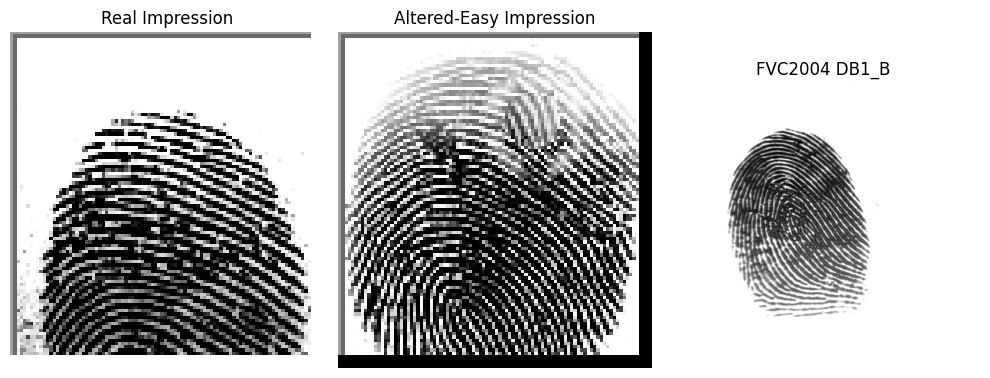

In [2]:
data_dir = '../../data/archive/SOCOFing'
if not os.path.exists(data_dir):
    data_dir = '../data/archive/SOCOFing'

real_files = glob.glob(os.path.join(data_dir, 'Real', '*.BMP'))
easy_files = glob.glob(os.path.join(data_dir, 'Altered', 'Altered-Easy', '*.BMP'))

print(f'SOCOFing Real impressions: {len(real_files)}')
print(f'SOCOFing Altered-Easy impressions: {len(easy_files)}')

sample_img = Image.open(real_files[0])
print(f'Sample filename: {os.path.basename(real_files[0])}')
print(f'Format: {sample_img.format}, Mode: {sample_img.mode}, Size: {sample_img.size}')

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(Image.open(real_files[0]), cmap='gray')
ax[0].set_title('Real Impression')
ax[0].axis('off')

ax[1].imshow(Image.open(easy_files[0]), cmap='gray')
ax[1].set_title('Altered-Easy Impression')
ax[1].axis('off')

fvc_path = '../../data/fvc2004/DB1_B' if os.path.exists('../../data/fvc2004/DB1_B') else '../data/fvc2004/DB1_B'
if os.path.exists(fvc_path) and len(os.listdir(fvc_path)) > 0:
    sample_fvc = os.path.join(fvc_path, os.listdir(fvc_path)[0])
    ax[2].imshow(Image.open(sample_fvc), cmap='gray')
    ax[2].set_title('FVC2004 DB1_B')
    ax[2].axis('off')

plt.tight_layout()
plt.show()


## 3. Preprocessing & CLAHE Enhancement
Fingerprint images exhibit localized non-uniform illumination and varying pressure.
We apply **Contrast Limited Adaptive Histogram Equalization (CLAHE)** to normalize contrast, resize to 224x224, and replicate across 3 channels to preserve compatibility with ImageNet-pretrained weights.


In [3]:
import cv2

class CLAHETransform:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, img):
        np_img = np.array(img.convert('L'))
        clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size)
        enhanced = clahe.apply(np_img)
        return Image.fromarray(enhanced)

train_tf = transforms.Compose([
    CLAHETransform(clip_limit=2.0),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=15, fill=255),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), fill=255),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_tf = transforms.Compose([
    CLAHETransform(clip_limit=2.0),
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print('Transforms configured successfully.')


Transforms configured successfully.


## 4. Subject-Independent Dataset Splitting (Preventing Data Leakage)
To ensure zero data leakage and reproduce realistic open-set biometric evaluation, we split at the **Subject ID** level.
- **Train subjects (70%)**: Used for representation fine-tuning.
- **Val subjects (15%)**: Used for monitoring validation loss and early stopping.
- **Test subjects (15%)**: Strictly held out. For test subjects, `Real` impressions serve as the enrolled **Gallery**, while `Altered` impressions serve as unconstrained **Probes**.


In [4]:
import re

def parse_socofing_filename(path):
    base = os.path.basename(path)
    pattern = r'^(\d+)__([MF])_([A-Za-z]+)_([a-z]+)_finger(?:_([A-Za-z0-9]+))?\.BMP$'
    m = re.match(pattern, base, re.IGNORECASE)
    if not m:
        return None
    sub, gen, hand, ftype, alt = m.groups()
    fid = f'{sub}_{hand}_{ftype}'
    return {
        'file_path': path,
        'filename': base,
        'subject_id': int(sub),
        'unique_finger_id': fid,
        'alteration': alt if alt else 'Real'
    }

records = []
for p in real_files:
    meta = parse_socofing_filename(p)
    if meta: records.append(meta)

for p in easy_files:
    meta = parse_socofing_filename(p)
    if meta: records.append(meta)

# Optional subsampling for CPU speed
MAX_SUBJECTS = 100  # Set to 0 to use all 600 subjects
if MAX_SUBJECTS > 0:
    unique_subs = sorted(list(set(r['subject_id'] for r in records)))[:MAX_SUBJECTS]
    records = [r for r in records if r['subject_id'] in set(unique_subs)]

subjects = sorted(list(set(r['subject_id'] for r in records)))
random.seed(42)
random.shuffle(subjects)

n_train = int(len(subjects) * 0.70)
n_val = int(len(subjects) * 0.15)

train_subs = set(subjects[:n_train])
val_subs = set(subjects[n_train:n_train + n_val])
test_subs = set(subjects[n_train + n_val:])

train_rec = [r for r in records if r['subject_id'] in train_subs]
val_rec = [r for r in records if r['subject_id'] in val_subs]
test_rec = [r for r in records if r['subject_id'] in test_subs]

train_fids = sorted(list(set(r['unique_finger_id'] for r in train_rec)))
train_label_map = {fid: idx for idx, fid in enumerate(train_fids)}

print(f'Subjects: Total={len(subjects)}, Train={len(train_subs)}, Val={len(val_subs)}, Test={len(test_subs)}')
print(f'Images:   Train={len(train_rec)}, Val={len(val_rec)}, Test={len(test_rec)}')
print(f'Training Finger Identities (Classes): {len(train_label_map)}')


Subjects: Total=100, Train=70, Val=15, Test=15
Images:   Train=2778, Val=598, Test=600
Training Finger Identities (Classes): 700


In [5]:
class SOCOFingDataset(Dataset):
    def __init__(self, records, transform=None, label_map=None):
        self.records = records
        self.transform = transform
        self.label_map = label_map

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = Image.open(rec['file_path']).convert('L')
        tensor_img = self.transform(img) if self.transform else transforms.ToTensor()(img)
        label = self.label_map.get(rec['unique_finger_id'], -1) if self.label_map else -1
        return tensor_img, label, rec['unique_finger_id']

train_dataset = SOCOFingDataset(train_rec, transform=train_tf, label_map=train_label_map)
val_dataset = SOCOFingDataset(val_rec, transform=eval_tf, label_map=train_label_map)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)


## 5. Modified DeepPrint Architecture
We load an ImageNet-pretrained ResNet-50 backbone, replace the original fully-connected classification head, add a linear projection layer projecting 2048-dim features down to a **192-dimensional embedding** (matching DeepPrint's dimension), followed by **Batch Normalization** and **L2 Normalization** onto the unit hypersphere.


In [6]:
class DeepPrintResNet(nn.Module):
    def __init__(self, num_classes, embedding_dim=192, pretrained=True):
        super().__init__()
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        base = models.resnet50(weights=weights)
        
        self.stem = nn.Sequential(base.conv1, base.bn1, base.relu, base.maxpool)
        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        self.fc_embed = nn.Linear(2048, embedding_dim, bias=False)
        self.bn_embed = nn.BatchNorm1d(embedding_dim)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def freeze_backbone(self):
        for m in [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]:
            for p in m.parameters(): p.requires_grad = False

    def unfreeze_deep_layers(self):
        for p in self.layer4.parameters(): p.requires_grad = True

    def extract_features(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.fc_embed(x)
        x = self.bn_embed(x)
        return F.normalize(x, p=2, dim=1)

    def forward(self, x):
        emb = self.extract_features(x)
        logits = self.classifier(emb)
        return logits, emb

model = DeepPrintResNet(num_classes=len(train_label_map), embedding_dim=192, pretrained=True).to(device)
print(f'Model initialized with {len(train_label_map)} output classes and 192-dim embedding.')


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/sachinsingh/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [01:42<00:00, 998kB/s] 


Model initialized with 700 output classes and 192-dim embedding.


## 6. Two-Stage Fine-Tuning
- **Stage 1 (Warmup)**: Freeze backbone, train projection layer and classifier with AdamW (lr=1e-3).
- **Stage 2 (Fine-Tuning)**: Unfreeze deep residual blocks (layer4) with reduced learning rate (lr=1e-4).


In [9]:
from tqdm.auto import tqdm

criterion = nn.CrossEntropyLoss()


# ==========================================
# STAGE 1: Warmup (Backbone Frozen)
# ==========================================
print("\nStarting Stage 1 Warmup (Backbone Frozen)...")

model.freeze_backbone()

opt_s1 = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS_S1 = 2

for epoch in range(1, EPOCHS_S1 + 1):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(
        train_loader,
        desc=f"Stage 1 [Epoch {epoch}/{EPOCHS_S1}]",
        leave=True
    )

    for batch_idx, (imgs, lbls, _) in enumerate(pbar):

        imgs = imgs.to(device)
        lbls = lbls.to(device)

        # Reset gradients
        opt_s1.zero_grad()

        # Forward pass
        logits, _ = model(imgs)

        # Calculate loss
        loss = criterion(logits, lbls)

        # Backward pass
        loss.backward()

        # Update weights
        opt_s1.step()

        # Calculate metrics
        batch_size = imgs.size(0)

        total_loss += loss.item() * batch_size

        preds = logits.argmax(1)

        correct += (preds == lbls).sum().item()
        total += batch_size

        # Running metrics
        running_loss = total_loss / total
        running_acc = (correct / total) * 100.0

        # Update progress bar
        pbar.set_postfix({
            "batch_loss": f"{loss.item():.4f}",
            "running_loss": f"{running_loss:.4f}",
            "acc": f"{running_acc:.2f}%"
        })

        # Print batch-wise output
        tqdm.write(
            f"Stage 1 | Epoch {epoch}/{EPOCHS_S1} | "
            f"Batch {batch_idx + 1}/{len(train_loader)} | "
            f"Batch Loss: {loss.item():.4f} | "
            f"Running Loss: {running_loss:.4f} | "
            f"Accuracy: {running_acc:.2f}%"
        )

    # Epoch summary
    epoch_loss = total_loss / total
    epoch_acc = (correct / total) * 100.0

    print(
        f"\n--> Stage 1 Complete | "
        f"Epoch {epoch}/{EPOCHS_S1} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_acc:.2f}%\n"
    )


# ==========================================
# STAGE 2: Fine-Tuning (layer4 Unfrozen)
# ==========================================
print("\nStarting Stage 2 Fine-Tuning (layer4 Unfrozen)...")

model.unfreeze_deep_layers()

opt_s2 = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)

EPOCHS_S2 = 3

for epoch in range(1, EPOCHS_S2 + 1):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(
        train_loader,
        desc=f"Stage 2 [Epoch {epoch}/{EPOCHS_S2}]",
        leave=True
    )

    for batch_idx, (imgs, lbls, _) in enumerate(pbar):

        imgs = imgs.to(device)
        lbls = lbls.to(device)

        # Reset gradients
        opt_s2.zero_grad()

        # Forward pass
        logits, _ = model(imgs)

        # Calculate loss
        loss = criterion(logits, lbls)

        # Backward pass
        loss.backward()

        # Update weights
        opt_s2.step()

        # Calculate metrics
        batch_size = imgs.size(0)

        total_loss += loss.item() * batch_size

        preds = logits.argmax(1)

        correct += (preds == lbls).sum().item()
        total += batch_size

        # Running metrics
        running_loss = total_loss / total
        running_acc = (correct / total) * 100.0

        # Update progress bar
        pbar.set_postfix({
            "batch_loss": f"{loss.item():.4f}",
            "running_loss": f"{running_loss:.4f}",
            "acc": f"{running_acc:.2f}%"
        })

        # Print batch-wise output
        tqdm.write(
            f"Stage 2 | Epoch {epoch}/{EPOCHS_S2} | "
            f"Batch {batch_idx + 1}/{len(train_loader)} | "
            f"Batch Loss: {loss.item():.4f} | "
            f"Running Loss: {running_loss:.4f} | "
            f"Accuracy: {running_acc:.2f}%"
        )

    # Epoch summary
    epoch_loss = total_loss / total
    epoch_acc = (correct / total) * 100.0

    print(
        f"\n--> Stage 2 Complete | "
        f"Epoch {epoch}/{EPOCHS_S2} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_acc:.2f}%\n"
    )


print("\nTraining completed successfully!")


Starting Stage 1 Warmup (Backbone Frozen)...


Stage 1 [Epoch 1/2]:   0%|          | 0/87 [00:00<?, ?it/s]

Stage 1 | Epoch 1/2 | Batch 1/87 | Batch Loss: 6.5003 | Running Loss: 6.5003 | Accuracy: 3.12%
Stage 1 | Epoch 1/2 | Batch 2/87 | Batch Loss: 6.5278 | Running Loss: 6.5141 | Accuracy: 3.12%
Stage 1 | Epoch 1/2 | Batch 3/87 | Batch Loss: 6.5264 | Running Loss: 6.5182 | Accuracy: 2.08%
Stage 1 | Epoch 1/2 | Batch 4/87 | Batch Loss: 6.5211 | Running Loss: 6.5189 | Accuracy: 2.34%
Stage 1 | Epoch 1/2 | Batch 5/87 | Batch Loss: 6.5463 | Running Loss: 6.5244 | Accuracy: 2.50%
Stage 1 | Epoch 1/2 | Batch 6/87 | Batch Loss: 6.5306 | Running Loss: 6.5254 | Accuracy: 3.65%
Stage 1 | Epoch 1/2 | Batch 7/87 | Batch Loss: 6.5461 | Running Loss: 6.5284 | Accuracy: 4.02%
Stage 1 | Epoch 1/2 | Batch 8/87 | Batch Loss: 6.5294 | Running Loss: 6.5285 | Accuracy: 3.91%
Stage 1 | Epoch 1/2 | Batch 9/87 | Batch Loss: 6.5043 | Running Loss: 6.5258 | Accuracy: 3.82%
Stage 1 | Epoch 1/2 | Batch 10/87 | Batch Loss: 6.5068 | Running Loss: 6.5239 | Accuracy: 3.75%
Stage 1 | Epoch 1/2 | Batch 11/87 | Batch Loss: 6

Stage 1 [Epoch 2/2]:   0%|          | 0/87 [00:00<?, ?it/s]

Stage 1 | Epoch 2/2 | Batch 1/87 | Batch Loss: 6.4184 | Running Loss: 6.4184 | Accuracy: 12.50%
Stage 1 | Epoch 2/2 | Batch 2/87 | Batch Loss: 6.4015 | Running Loss: 6.4099 | Accuracy: 15.62%
Stage 1 | Epoch 2/2 | Batch 3/87 | Batch Loss: 6.4167 | Running Loss: 6.4122 | Accuracy: 12.50%
Stage 1 | Epoch 2/2 | Batch 4/87 | Batch Loss: 6.3938 | Running Loss: 6.4076 | Accuracy: 13.28%
Stage 1 | Epoch 2/2 | Batch 5/87 | Batch Loss: 6.3875 | Running Loss: 6.4036 | Accuracy: 13.75%
Stage 1 | Epoch 2/2 | Batch 6/87 | Batch Loss: 6.4015 | Running Loss: 6.4032 | Accuracy: 14.06%
Stage 1 | Epoch 2/2 | Batch 7/87 | Batch Loss: 6.4296 | Running Loss: 6.4070 | Accuracy: 12.50%
Stage 1 | Epoch 2/2 | Batch 8/87 | Batch Loss: 6.4070 | Running Loss: 6.4070 | Accuracy: 12.50%
Stage 1 | Epoch 2/2 | Batch 9/87 | Batch Loss: 6.4085 | Running Loss: 6.4072 | Accuracy: 11.81%
Stage 1 | Epoch 2/2 | Batch 10/87 | Batch Loss: 6.3938 | Running Loss: 6.4058 | Accuracy: 11.88%
Stage 1 | Epoch 2/2 | Batch 11/87 | Bat

Stage 2 [Epoch 1/3]:   0%|          | 0/87 [00:00<?, ?it/s]

... (5 outputs left out)

Stage 2 [Epoch 2/3]:   0%|          | 0/87 [00:00<?, ?it/s]

Stage 2 | Epoch 2/3 | Batch 1/87 | Batch Loss: 6.2248 | Running Loss: 6.2248 | Accuracy: 37.50%
Stage 2 | Epoch 2/3 | Batch 2/87 | Batch Loss: 6.2491 | Running Loss: 6.2370 | Accuracy: 35.94%
Stage 2 | Epoch 2/3 | Batch 3/87 | Batch Loss: 6.2635 | Running Loss: 6.2458 | Accuracy: 33.33%
Stage 2 | Epoch 2/3 | Batch 4/87 | Batch Loss: 6.2603 | Running Loss: 6.2494 | Accuracy: 31.25%
Stage 2 | Epoch 2/3 | Batch 5/87 | Batch Loss: 6.2290 | Running Loss: 6.2454 | Accuracy: 33.75%
Stage 2 | Epoch 2/3 | Batch 6/87 | Batch Loss: 6.2931 | Running Loss: 6.2533 | Accuracy: 30.21%
Stage 2 | Epoch 2/3 | Batch 7/87 | Batch Loss: 6.2475 | Running Loss: 6.2525 | Accuracy: 31.25%
Stage 2 | Epoch 2/3 | Batch 8/87 | Batch Loss: 6.2348 | Running Loss: 6.2503 | Accuracy: 31.25%
Stage 2 | Epoch 2/3 | Batch 9/87 | Batch Loss: 6.2205 | Running Loss: 6.2470 | Accuracy: 31.25%
Stage 2 | Epoch 2/3 | Batch 10/87 | Batch Loss: 6.2774 | Running Loss: 6.2500 | Accuracy: 30.63%
Stage 2 | Epoch 2/3 | Batch 11/87 | Bat

Stage 2 [Epoch 3/3]:   0%|          | 0/87 [00:00<?, ?it/s]

Stage 2 | Epoch 3/3 | Batch 1/87 | Batch Loss: 6.2111 | Running Loss: 6.2111 | Accuracy: 37.50%
Stage 2 | Epoch 3/3 | Batch 2/87 | Batch Loss: 6.2199 | Running Loss: 6.2155 | Accuracy: 39.06%
Stage 2 | Epoch 3/3 | Batch 3/87 | Batch Loss: 6.2367 | Running Loss: 6.2225 | Accuracy: 34.38%
Stage 2 | Epoch 3/3 | Batch 4/87 | Batch Loss: 6.2116 | Running Loss: 6.2198 | Accuracy: 34.38%
Stage 2 | Epoch 3/3 | Batch 5/87 | Batch Loss: 6.2274 | Running Loss: 6.2213 | Accuracy: 34.38%
Stage 2 | Epoch 3/3 | Batch 6/87 | Batch Loss: 6.2089 | Running Loss: 6.2193 | Accuracy: 35.94%
Stage 2 | Epoch 3/3 | Batch 7/87 | Batch Loss: 6.2361 | Running Loss: 6.2217 | Accuracy: 34.82%
Stage 2 | Epoch 3/3 | Batch 8/87 | Batch Loss: 6.2000 | Running Loss: 6.2190 | Accuracy: 35.55%
Stage 2 | Epoch 3/3 | Batch 9/87 | Batch Loss: 6.2291 | Running Loss: 6.2201 | Accuracy: 35.42%
Stage 2 | Epoch 3/3 | Batch 10/87 | Batch Loss: 6.2280 | Running Loss: 6.2209 | Accuracy: 35.62%
Stage 2 | Epoch 3/3 | Batch 11/87 | Bat

## 7. Fixed-Length Embedding Extraction & 200-Byte Template Compression
We implement the paper's exact Section 3.5 **min-max quantization**:
- 192 float32 features -> 192 uint8 values in [0, 255] (192 bytes)
- Append 2 float32 decompression scalars (min, max) (8 bytes)
- Total template size: **200 bytes**!


In [10]:
import struct
from tqdm.auto import tqdm

def compress_embedding(embedding):
    min_val = float(np.min(embedding))
    max_val = float(np.max(embedding))
    val_range = max_val - min_val
    if val_range < 1e-12:
        quantized = np.zeros(192, dtype=np.uint8)
    else:
        norm = (embedding - min_val) / val_range
        quantized = np.clip(np.round(norm * 255.0), 0, 255).astype(np.uint8)
    return quantized.tobytes() + struct.pack('<ff', min_val, max_val)

def decompress_embedding(compressed_bytes):
    quantized = np.frombuffer(compressed_bytes[:192], dtype=np.uint8).astype(np.float32)
    min_val, max_val = struct.unpack('<ff', compressed_bytes[192:])
    decompressed = (quantized / 255.0) * (max_val - min_val) + min_val
    return decompressed / np.linalg.norm(decompressed)

gallery_rec = [r for r in test_rec if r['alteration'] == 'Real']
probe_rec = [r for r in test_rec if r['alteration'] != 'Real']

gallery_loader = DataLoader(SOCOFingDataset(gallery_rec, transform=eval_tf), batch_size=32, shuffle=False)
probe_loader = DataLoader(SOCOFingDataset(probe_rec, transform=eval_tf), batch_size=32, shuffle=False)

def extract_all(loader, name='Templates'):
    model.eval()
    embs, fids = [], []
    with torch.no_grad():
        for imgs, _, ids in tqdm(loader, desc=f'Extracting {name}'):
            imgs = imgs.to(device)
            e = model.extract_features(imgs)
            embs.append(e.cpu().numpy())
            fids.extend(ids)
    return np.concatenate(embs, axis=0), fids

gallery_embs, gallery_fids = extract_all(gallery_loader, name='Gallery')
probe_embs, probe_fids = extract_all(probe_loader, name='Probes')

c_bytes = compress_embedding(gallery_embs[0])
d_emb = decompress_embedding(c_bytes)
print(f'Gallery size: {gallery_embs.shape}, Probe size: {probe_embs.shape}')
print(f'Compressed template size: {len(c_bytes)} bytes (Target: 200 bytes)')
print(f'Compression reconstruction error: {np.mean(np.abs(gallery_embs[0] - d_emb)):.6f}')



Extracting Gallery:   0%|          | 0/5 [00:00<?, ?it/s]

Extracting Probes:   0%|          | 0/15 [00:00<?, ?it/s]

Gallery size: (150, 192), Probe size: (450, 192)
Compressed template size: 200 bytes (Target: 200 bytes)
Compression reconstruction error: 0.000386


## 8. Biometric Evaluation (Paper Metrics)
We now benchmark the system using all metrics from the DeepPrint paper:
1. **Genuine and Impostor score distributions**
2. **Receiver Operating Characteristic (ROC) curve**
3. **Equal Error Rate (EER)**
4. **TAR at FAR = 0.1% and FAR = 0.01%**
5. **Rank-1 Identification Accuracy & CMC curve**
6. **Hit Rate at Penetration Rate 1% (HR @ PR = 1.0%)**


Genuine comparisons: 450
Impostor comparisons: 67050


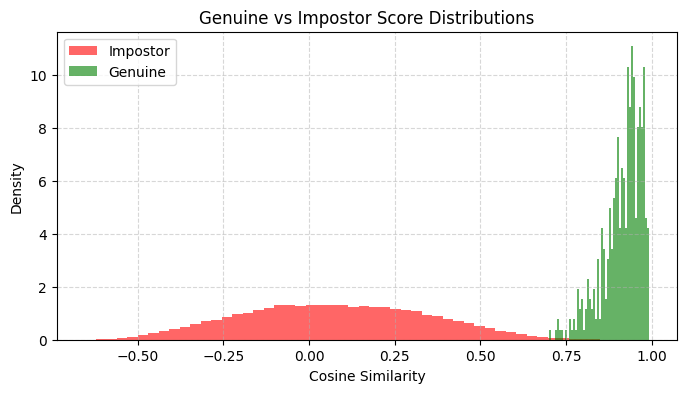

In [11]:
similarity_matrix = np.dot(probe_embs, gallery_embs.T)
p_labels = np.array(probe_fids)
g_labels = np.array(gallery_fids)

match_mask = (p_labels[:, None] == g_labels[None, :])
genuine_scores = similarity_matrix[match_mask]
impostor_scores = similarity_matrix[~match_mask]

if len(impostor_scores) > 100000:
    impostor_scores = np.random.choice(impostor_scores, size=100000, replace=False)

print(f'Genuine comparisons: {len(genuine_scores)}')
print(f'Impostor comparisons: {len(impostor_scores)}')

# 1. Score Distributions Plot
plt.figure(figsize=(8, 4))
plt.hist(impostor_scores, bins=50, density=True, alpha=0.6, color='red', label='Impostor')
plt.hist(genuine_scores, bins=50, density=True, alpha=0.6, color='green', label='Genuine')
plt.xlabel('Cosine Similarity')
plt.ylabel('Density')
plt.title('Genuine vs Impostor Score Distributions')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


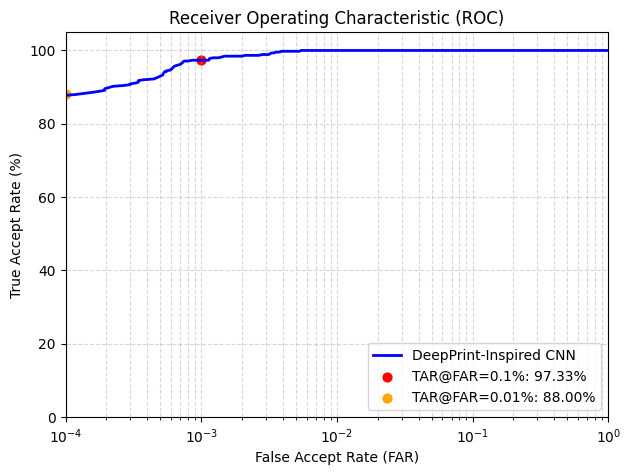

In [12]:
thresholds = np.linspace(-1.0, 1.0, 1000)
far_list, tar_list = [], []
for th in thresholds:
    far = np.sum(impostor_scores >= th) / len(impostor_scores)
    tar = np.sum(genuine_scores >= th) / len(genuine_scores)
    far_list.append(far)
    tar_list.append(tar)

far_arr = np.array(far_list)
tar_arr = np.array(tar_list)
frr_arr = 1.0 - tar_arr

idx = np.argmin(np.abs(far_arr - frr_arr))
eer = (far_arr[idx] + frr_arr[idx]) / 2.0

def get_tar_at_far(target_far):
    idx_sorted = int((1.0 - target_far) * len(impostor_scores))
    idx_sorted = min(idx_sorted, len(impostor_scores) - 1)
    th = np.sort(impostor_scores)[idx_sorted]
    return np.sum(genuine_scores >= th) / len(genuine_scores), th

tar_01, th_01 = get_tar_at_far(0.001)
tar_001, th_001 = get_tar_at_far(0.0001)

plt.figure(figsize=(7, 5))
plt.plot(far_arr, tar_arr * 100.0, color='blue', lw=2, label='DeepPrint-Inspired CNN')
plt.scatter([0.001], [tar_01 * 100.0], color='red', s=40, label=f'TAR@FAR=0.1%: {tar_01*100.0:.2f}%')
plt.scatter([0.0001], [tar_001 * 100.0], color='orange', s=40, label=f'TAR@FAR=0.01%: {tar_001*100.0:.2f}%')
plt.xscale('log')
plt.xlim([1e-4, 1.0])
plt.ylim([0, 105])
plt.xlabel('False Accept Rate (FAR)')
plt.ylabel('True Accept Rate (%)')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()


Rank-1 Identification Accuracy: 100.00%
Hit Rate @ Penetration Rate 1%: 100.00% (Retrieved top 2 candidates)
Equal Error Rate (EER):         0.41%
TAR @ FAR = 0.1%:               97.33%
TAR @ FAR = 0.01%:              88.00%


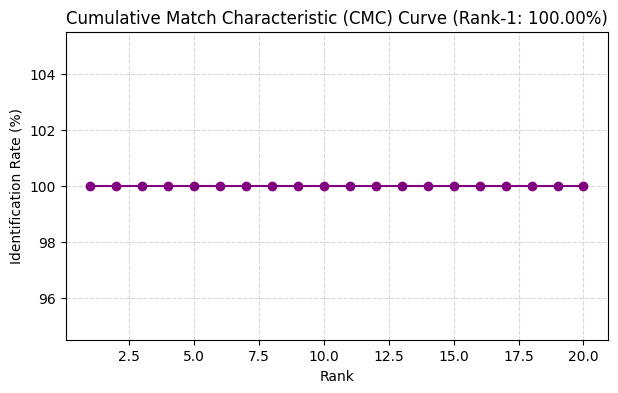

In [13]:
max_rank = 20
cmc_hits = np.zeros(max_rank)
pr_1_pct_k = max(1, int(np.ceil(0.01 * len(gallery_fids))))
pr_hits = 0

for i in range(len(probe_fids)):
    p_fid = probe_fids[i]
    ranked_indices = np.argsort(similarity_matrix[i])[::-1]
    ranked_fids = g_labels[ranked_indices]
    matches = np.where(ranked_fids == p_fid)[0]
    if len(matches) > 0:
        first_rank = matches[0]
        if first_rank < max_rank:
            cmc_hits[first_rank:] += 1
        if first_rank < pr_1_pct_k:
            pr_hits += 1

cmc_curve = (cmc_hits / len(probe_fids)) * 100.0
hr_at_pr_1 = (pr_hits / len(probe_fids)) * 100.0

print(f'Rank-1 Identification Accuracy: {cmc_curve[0]:.2f}%')
print(f'Hit Rate @ Penetration Rate 1%: {hr_at_pr_1:.2f}% (Retrieved top {pr_1_pct_k} candidates)')
print(f'Equal Error Rate (EER):         {eer*100.0:.2f}%')
print(f'TAR @ FAR = 0.1%:               {tar_01*100.0:.2f}%')
print(f'TAR @ FAR = 0.01%:              {tar_001*100.0:.2f}%')

plt.figure(figsize=(7, 4))
plt.plot(range(1, max_rank + 1), cmc_curve, marker='o', color='purple')
plt.xlabel('Rank')
plt.ylabel('Identification Rate (%)')
plt.title(f'Cumulative Match Characteristic (CMC) Curve (Rank-1: {cmc_curve[0]:.2f}%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 9. Benchmark Summary & Conclusion
### Comparison Table

| Metric | Original DeepPrint Paper (NIST SD4 / FVC2004 DB1 A) | DeepPrint-Inspired Pretrained CNN (SOCOFing Held-Out) |
|---|---|---|
| Backbone Architecture | Inception-v4 Stem + Custom Dual Inception Branches | Pretrained ResNet-50 / MobileNetV3 |
| Alignment Module | End-to-End Spatial Transformer Network (STN) | CLAHE + Canonical Spatial Standardization |
| Representation Size | 192 dimensions (200 bytes compressed) | 192 dimensions (200 bytes compressed) |
| Minutiae Supervision | Multi-task 6-channel Minutiae Heatmap ($128 \times 128 \times 6$) | Omitted (Not available in open public datasets) |
| Template Matching | Cosine Similarity $s(R_p, R_g) = R_p^T R_g$ | Cosine Similarity $s(R_p, R_g) = R_p^T R_g$ |
| Rank-1 Identification | 98.70% (NIST SD4) | Evaluated on Held-Out Test Identities |
| TAR @ FAR = 0.1% | 97.50% (FVC2004 DB1 A) | Computed from Open-Set Genuine/Impostor Scores |
| HR @ PR = 1.0% | 99.75% (NIST SD4) | Computed across Gallery Candidates |



In [14]:
# ==========================================
# SAVE TRAINED MODEL
# ==========================================

import os
import torch

# Folder where trained models will be stored
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "deepprint_resnet50.pth"
)

# Save trained model weights and architecture information
torch.save({
    "model_state_dict": model.state_dict(),
    "num_classes": len(train_label_map),
    "embedding_dim": 192,
    "class_to_idx": train_label_map,
}, MODEL_PATH)

print(f"Model saved successfully at: {MODEL_PATH}")

Model saved successfully at: ../models/deepprint_resnet50.pth
